In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/content/dataset.csv")

In [ ]:
print(df.shape)
print(df.columns.tolist())
df.head()

In [36]:
tracks = df.sample(n=100, random_state = 42).reset_index(drop=True)
tracks = tracks.rename(columns={
    "track_id": "spotify_id",
    "track_name": "title",
    "artists": "artist",
    "album_name": "album",
    "track_genre": "genre",
})
tracks.head()

,Unnamed: 0,spotify_id,artist,album,title,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genre
0,113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,...,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
1,42819,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,...,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
2,59311,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,...,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
3,91368,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,...,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
4,61000,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,...,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


In [ ]:
tracks["duration_sec"] = (tracks["duration_ms"] / 1000).round(2)

In [ ]:
tracks = tracks.drop_duplicates(subset = ["title", "artist"]).reset_index(drop=True)

In [39]:
import sqlite3

In [40]:
con = sqlite3.connect("spotify.db")
cur = con.cursor()

In [41]:
cur.executescript("""
CREATE TABLE IF NOT EXISTS artists (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT NOT NULL UNIQUE
);
CREATE TABLE IF NOT EXISTS albums (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    title TEXT NOT NULL,
    artist_id INTEGER REFERENCES artists(id),
    UNIQUE(title, artist_id)
);
CREATE TABLE IF NOT EXISTS genres (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT NOT NULL UNIQUE
);
CREATE TABLE IF NOT EXISTS tracks (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    spotify_id TEXT UNIQUE,
    title TEXT NOT NULL,
    artist_id INTEGER REFERENCES artists(id),
    album_id INTEGER REFERENCES albums(id),
    genre_id INTEGER REFERENCES genres(id),
    popularity INTEGER,
    duration_sec REAL,
    explicit INTEGER,
    danceability REAL,
    energy REAL,
    tempo REAL,
    key INTEGER,
    loudness REAL,
    valence REAL
);
""")

In [42]:
def get_id(table, name, extra=None):
    if name is None or (isinstance(name, float) and pd.isna(name)):
        return None
    cur.execute(f"SELECT id FROM {table} WHERE name=?", (name,))
    row = cur.fetchone()
    if row: return row[0]
    cur.execute(f"INSERT INTO {table} (name) VALUES (?)", (name,))
    return cur.lastrowid

In [43]:
def get_album_id(title, artist_id):
    if not title: return None
    cur.execute("SELECT id FROM albums WHERE title=? AND artist_id IS ?",
                (title, artist_id))
    row = cur.fetchone()
    if row: return row[0]
    cur.execute("INSERT INTO albums (title, artist_id) VALUES (?,?)",
                (title, artist_id))
    return cur.lastrowid

In [44]:
for _, r in tracks.iterrows():
    artist_id = get_id("artists", r["artist"])
    album_id  = get_album_id(r["album"], artist_id)
    genre_id  = get_id("genres", r["genre"])
    cur.execute("""INSERT OR IGNORE INTO tracks
        (spotify_id, title, artist_id, album_id, genre_id,
         popularity, duration_sec, explicit,
         danceability, energy, tempo, key, loudness, valence)
        VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?)""",
        (r["spotify_id"], r["title"], artist_id, album_id, genre_id,
         int(r["popularity"]) if pd.notna(r["popularity"]) else None,
         r["duration_sec"], int(r["explicit"]),
         r["danceability"], r["energy"], r["tempo"],
         r["key"], r["loudness"], r["valence"]))
con.commit()
con.close()

В качестве источника я использовала базу данных с kaggle "Spotify Tracks Dataset", в которой было представлено порядка 1000 песен.
Для чистоты эксперимента я добавляла в таблицу песни рандомно. В самой таблице в моем случае представлено 68 жанров. Никаких ограничений по артистам и жанрам пока не стоит, так как в изначальном датасете было представлено около 120 жанров.

Задание 2

Первый признаком мы возьмем эмоциональную окраску. Ее мы выведем из двух параметров изначальной таблицы: valency и energy. В результате получим 4 катеории: счастливая-спокойная, счастливая-энергичная, грустная-энергичная и грустная-спокойная.
Вторым признаком возьмем темп и поделим на три категории: медленный, нормальный и быстрый(в качестве ограничителя возьмем значения в 90 и 120)
Третьим признаком возьмем энергичность. Ее также поделим на 3 категории: низкая, средняя и высокая.
Четвертым - атмосферность музыки, которую будем определять по количеству интрументала, речевой части, энергичности.
А пятым - к чему музыка подходит: для занятий спорта, для вечеринки, отдыха...
Такая категоризация полезна для дальнейшего создания рекомендаций, в соотвествии с желаниями пользователя

In [45]:
def get_mood(valence, energy):
    if pd.isna(valence) or pd.isna(energy):
        return None
    if valence >= 0.5 and energy >= 0.5:
        return "happy_energetic"
    elif valence >= 0.5 and energy < 0.5:
        return "happy_calm"
    elif valence < 0.5 and energy >= 0.5:
        return "sad_energetic"
    else:
        return "sad_calm"

In [46]:
def get_tempo_category(tempo):
    if pd.isna(tempo):
        return None
    if tempo < 90:
        return "slow"
    elif tempo < 120:
        return "medium"
    else:
        return "fast"


In [47]:
def get_energy_level(energy):
    if pd.isna(energy):
        return None
    if energy < 0.4:
        return "low"
    elif energy < 0.7:
        return "medium"
    else:
        return "high"

In [48]:
def get_atmosphere(acousticness, instrumentalness, speechiness, energy):
    if pd.isna(acousticness):
        return None
    if acousticness >= 0.7:
        return "acoustic"
    if instrumentalness >= 0.5 and energy < 0.5:
        return "ambient"
    if speechiness >= 0.5:
        return "spoken"
    if energy >= 0.7 and acousticness < 0.3:
        return "electronic"
    return "studio"


In [49]:
def get_use_case(energy, tempo, valence, acousticness):
    if pd.isna(energy):
        return None
    if energy >= 0.7 and tempo >= 120:
        return "workout"
    if energy >= 0.7 and valence >= 0.5:
        return "party"
    if energy < 0.4 and acousticness >= 0.5:
        return "study"
    if energy < 0.4 and valence < 0.4:
        return "sleep"
    return "commute"

In [50]:
tracks = tracks.copy()

tracks["mood"] = tracks.apply(lambda r: get_mood(r["valence"], r["energy"]), axis=1)
tracks["tempo_category"] = tracks["tempo"].apply(get_tempo_category)
tracks["energy_level"] = tracks["energy"].apply(get_energy_level)
tracks["atmosphere"] = tracks.apply(
    lambda r: get_atmosphere(r["acousticness"], r["instrumentalness"],
                             r["speechiness"], r["energy"]), axis=1)
tracks["use_case"]       = tracks.apply(
    lambda r: get_use_case(r["energy"], r["tempo"],
                           r["valence"], r["acousticness"]), axis=1)

tracks["era"] = "unknown"

In [51]:
print(tracks[["title", "genre", "mood", "use_case",
              "atmosphere", "tempo_category", "energy_level"]].head(10))

                                 title        genre             mood use_case  \
0                        No Other Name  world-music    sad_energetic  commute   
1                       Failed Organum    grindcore    sad_energetic  workout   
2                Save the Trees, Pt. 1      iranian    sad_energetic  commute   
3                      Merry Christmas         rock  happy_energetic  commute   
4                                月の大きさ       j-idol  happy_energetic    party   
5               Jah Jah Revolta, Pt. 2        samba  happy_energetic  workout   
6            Please Stop Communicating       comedy  happy_energetic    party   
7                    A Form of Protest    metalcore    sad_energetic  commute   
8               I'm Ready - Radio Edit        disco  happy_energetic  workout   
9  Proibida Pra Mim (Grazon) - Ao Vivo        r-n-b  happy_energetic  workout   

   atmosphere tempo_category energy_level  
0      studio           fast       medium  
1  electronic       

Задание 3

Лучше всего подходит гибридный пайплайн, который сочетает правила и LLM. Правила здесь необхоидмы для определения признаков (как мы делали в задании 2). LLM будет уточнять по трекам параметры, так как правила не понимают семантики. Модель может определить категорию по контексту, в отличие от программы. Далее выполнено согласование и слиянине. Выбрано это также по причине прозрачности, детерминации и бесплатности.

Для LLM-обогащения я выбрала Groq + gpr-oss-20b. Выбрала я их по нескольким причинам. Во-первых, достаточно большое количество бесплатных токенов в день. Во-вторых,  модель передает структурированный JSON, что в нашем случае необходимо.

Для альтернатив для уровня правил я рассматривала обученный классификатор, но для него необходимо разметка данных и обучение, что не имело особого смысла, при написанных ранее правилах. В случае с LLM некоторые модели были отклонены в силу платности, google gemini 1.5 flash также мною рассматривался, но харакетристики выбранной модели меня устроили больше, поэтому данная модель была отложена на случай недоступности Groq

In [53]:
!pip install -q groq

In [54]:
import os, json, sqlite3
from groq import Groq

In [55]:
os.environ["GROQ_API_KEY"] = "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"
client = Groq(api_key=os.environ["GROQ_API_KEY"])

In [56]:
models = client.models.list()
for m in models.data:
    print(m.id, "—", getattr(m, "context_window", "?"), "tok")

whisper-large-v3-turbo — 448 tok
meta-llama/llama-prompt-guard-2-86m — 512 tok
qwen/qwen3.8-27b — 131072 tok
whisper-large-v3 — 448 tok
openai/gpt-oss-120b — 131072 tok
openai/gpt-oss-20b — 131072 tok
openai/gpt-oss-safeguard-20b — 131072 tok
allam-2-7b — 4096 tok
canopylabs/orpheus-arabic-saudi — 4000 tok
meta-llama/llama-prompt-guard-2-22m — 512 tok
canopylabs/orpheus-v1-english — 4000 tok


In [57]:
resp = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[{"role": "user", "content":
        'Верни JSON без markdown и пояснений: {"mood": "happy", "energy": "high"}'}],
    temperature=0,
    response_format={"type": "json_object"},   # ← JSON-режим
    max_tokens=200,
)
data = json.loads(resp.choices[0].message.content)
print(data)
print("Тип:", type(data))

{'mood': 'happy', 'energy': 'high'}
Тип: <class 'dict'>


In [58]:
PROMPT = """Ты музыкальный эксперт. По метаданным трека определи семантические характеристики.
Верни СТРОГО валидный JSON без markdown.

Допустимые значения:
- mood: happy_energetic, happy_calm, sad_energetic, sad_calm, aggressive, romantic, dreamy, melancholic
- use_case: workout, party, study, sleep, commute, romantic_dinner, coding, background
- atmosphere: acoustic, electronic, ambient, spoken, studio, cinematic, lo-fi, dark
- era: 60s, 70s, 80s, 90s, 2000s, 2010s, 2020s, unknown

Трек: "{title}" — {artist}, жанр {genre}, BPM {tempo}, energy {energy}, valence {valence}

Ответ: {{"mood": "...", "use_case": "...", "atmosphere": "...", "era": "..."}}"""

In [59]:
CACHE = "llm_cache.db"
with sqlite3.connect(CACHE) as c:
    c.execute("CREATE TABLE IF NOT EXISTS llm_cache (spotify_id TEXT PRIMARY KEY, response TEXT)")

In [60]:
def llm_predict(row):
    with sqlite3.connect(CACHE) as c:
        cached = c.execute("SELECT response FROM llm_cache WHERE spotify_id=?",
                           (row["spotify_id"],)).fetchone()
    if cached:
        return json.loads(cached[0])

    prompt = PROMPT.format(
        title=row["title"], artist=row["artist"], genre=row["genre"],
        tempo=row["tempo"], energy=row["energy"], valence=row["valence"]
    )
    try:
        resp = client.chat.completions.create(
            model="openai/gpt-oss-20b",
            messages=[{"role": "user", "content": prompt}],
            temperature=0,
            response_format={"type": "json_object"},
            max_tokens=500,
        )
        data = json.loads(resp.choices[0].message.content)
    except Exception as e:
        print("Groq error:", row["spotify_id"], e)
        data = {"mood": None, "use_case": None, "atmosphere": None, "era": None}

    with sqlite3.connect(CACHE) as c:
        c.execute("INSERT OR REPLACE INTO llm_cache VALUES (?, ?)",
                  (row["spotify_id"], json.dumps(data)))
    return data

In [61]:
!pip install -q tqdm

In [63]:
from tqdm.auto import tqdm

In [64]:
llm_results = [llm_predict(r) for _, r in tqdm(tracks.iterrows(), total=len(tracks))]

tracks["mood_llm"]       = [r["mood"]       for r in llm_results]
tracks["use_case_llm"]   = [r["use_case"]   for r in llm_results]
tracks["atmosphere_llm"] = [r["atmosphere"] for r in llm_results]
tracks["era"]            = [r["era"]        for r in llm_results]

  0%|          | 0/100 [00:00<?, ?it/s]

Задание 4

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110

In [67]:
print(tracks.columns.tolist())
print(tracks.shape)

['Unnamed: 0', 'spotify_id', 'artist', 'album', 'title', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'genre', 'duration_sec', 'mood', 'tempo_category', 'energy_level', 'atmosphere', 'use_case', 'era', 'mood_llm', 'use_case_llm', 'atmosphere_llm']
(100, 31)


Классический график распрделения по жанрам не очень хорошо здесь подоходит, так как в выборке встречается 68 жанров и график получается нечитаемым, поэтому я выбрала сделать логарифмический, так как по нему тоже можно определить распределение.

/tmp/ipykernel_1427/723032435.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.values, y=genre_counts.index, palette="viridis")


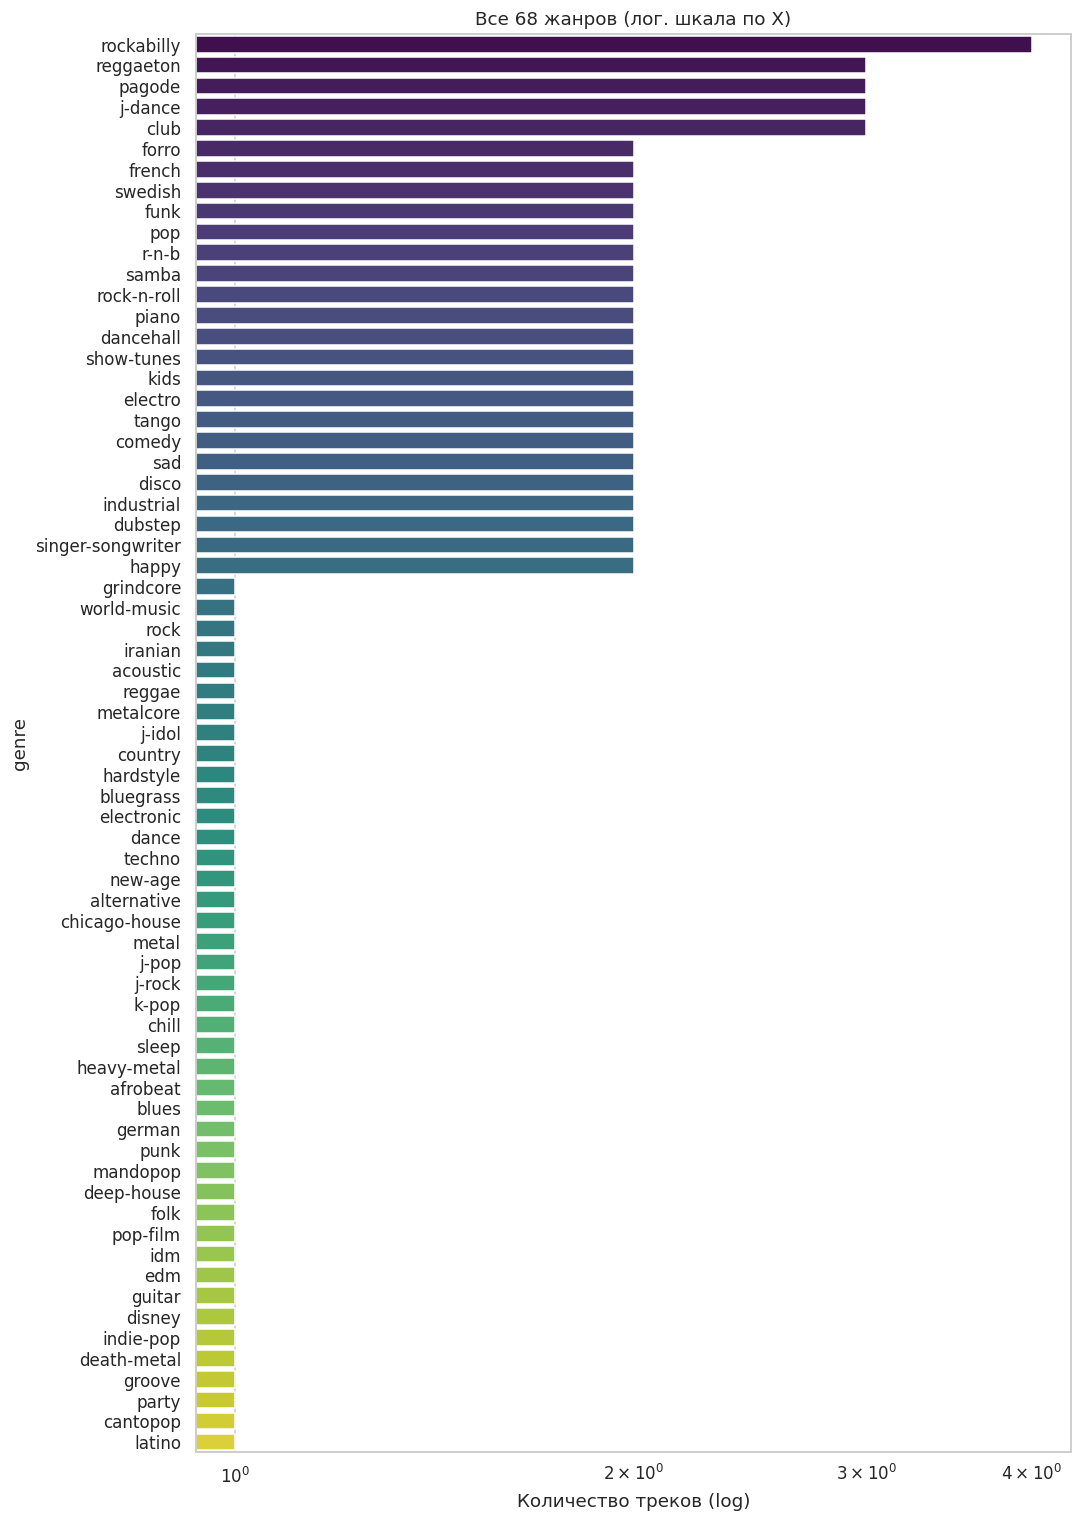

In [85]:
plt.figure(figsize=(10, 14))
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette="viridis")
plt.xscale("log")
plt.title(f"Все {len(genre_counts)} жанров (лог. шкала по X)")
plt.xlabel("Количество треков (log)")
plt.tight_layout()
plt.show()

In [71]:
def get_mood(v, e):
    if pd.isna(v) or pd.isna(e): return None
    if v >= 0.5 and e >= 0.5: return "happy_energetic"
    if v >= 0.5 and e <  0.5: return "happy_calm"
    if v <  0.5 and e >= 0.5: return "sad_energetic"
    return "sad_calm"

In [72]:
def get_tempo_category(t):
    if pd.isna(t): return None
    return "slow" if t < 90 else ("medium" if t < 120 else "fast")

In [73]:
def get_energy_level(e):
    if pd.isna(e): return None
    return "low" if e < 0.4 else ("medium" if e < 0.7 else "high")

In [74]:
def get_atmosphere(ac, instr, sp, e):
    if pd.isna(ac): return None
    if ac >= 0.7: return "acoustic"
    if instr >= 0.5 and e < 0.5: return "ambient"
    if sp >= 0.5: return "spoken"
    if e >= 0.7 and ac < 0.3: return "electronic"
    return "studio"


In [75]:
def get_use_case(e, t, v, ac):
    if pd.isna(e): return None
    if e >= 0.7 and t >= 120: return "workout"
    if e >= 0.7 and v >= 0.5: return "party"
    if e <  0.4 and ac >= 0.5: return "study"
    if e <  0.4 and v <  0.4: return "sleep"
    return "commute"

In [76]:
tracks["mood_rule"]       = tracks.apply(lambda r: get_mood(r["valence"], r["energy"]), axis=1)
tracks["tempo_category"]  = tracks["tempo"].apply(get_tempo_category)
tracks["energy_level"]    = tracks["energy"].apply(get_energy_level)
tracks["atmosphere_rule"] = tracks.apply(lambda r: get_atmosphere(r["acousticness"], r["instrumentalness"], r["speechiness"], r["energy"]), axis=1)
tracks["use_case_rule"]   = tracks.apply(lambda r: get_use_case(r["energy"], r["tempo"], r["valence"], r["acousticness"]), axis=1)

print("Правила посчитаны")
print(tracks[["title", "mood_rule", "use_case_rule", "atmosphere_rule"]].head())

Правила посчитаны
                   title        mood_rule use_case_rule atmosphere_rule
0          No Other Name    sad_energetic       commute          studio
1         Failed Organum    sad_energetic       workout      electronic
2  Save the Trees, Pt. 1    sad_energetic       commute          studio
3        Merry Christmas  happy_energetic       commute          studio
4                  月の大きさ  happy_energetic         party          studio


/tmp/ipykernel_1427/3371485570.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mood_llm_counts.values, y=mood_llm_counts.index,


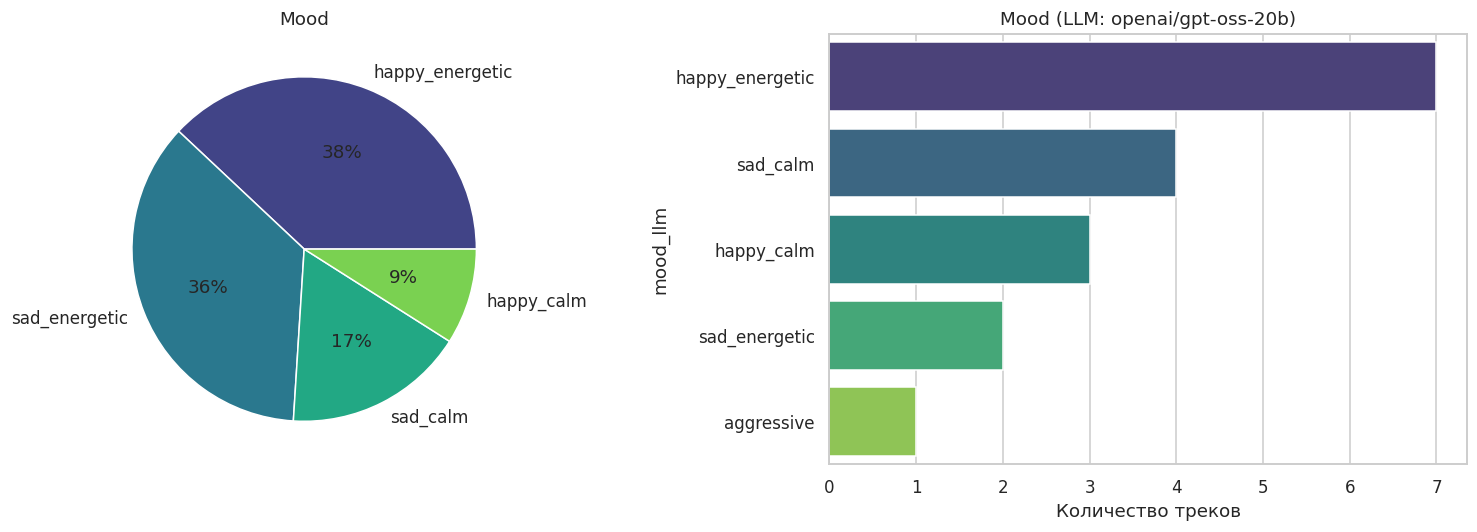

Согласие правил и LLM по mood: 12.0%


In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mood_rule_counts = tracks["mood_rule"].value_counts()
axes[0].pie(mood_rule_counts.values, labels=mood_rule_counts.index,
            autopct="%1.0f%%", colors=sns.color_palette("viridis", len(mood_rule_counts)))
axes[0].set_title("Mood")

mood_llm_counts = tracks["mood_llm"].value_counts().head(8)
sns.barplot(x=mood_llm_counts.values, y=mood_llm_counts.index,
            palette="viridis", ax=axes[1])
axes[1].set_title("Mood (LLM: openai/gpt-oss-20b)")
axes[1].set_xlabel("Количество треков")

plt.tight_layout()
plt.show()

if "mood" in tracks.columns:
    agree = (tracks["mood_rule"] == tracks["mood_llm"]).mean()
    print(f"Согласие правил и LLM по mood: {agree:.1%}")

/tmp/ipykernel_1427/3453616637.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=use_rule.index, y=use_rule.values, palette="viridis", ax=axes[0])
/tmp/ipykernel_1427/3453616637.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=use_llm.index, y=use_llm.values, palette="viridis", ax=axes[1])


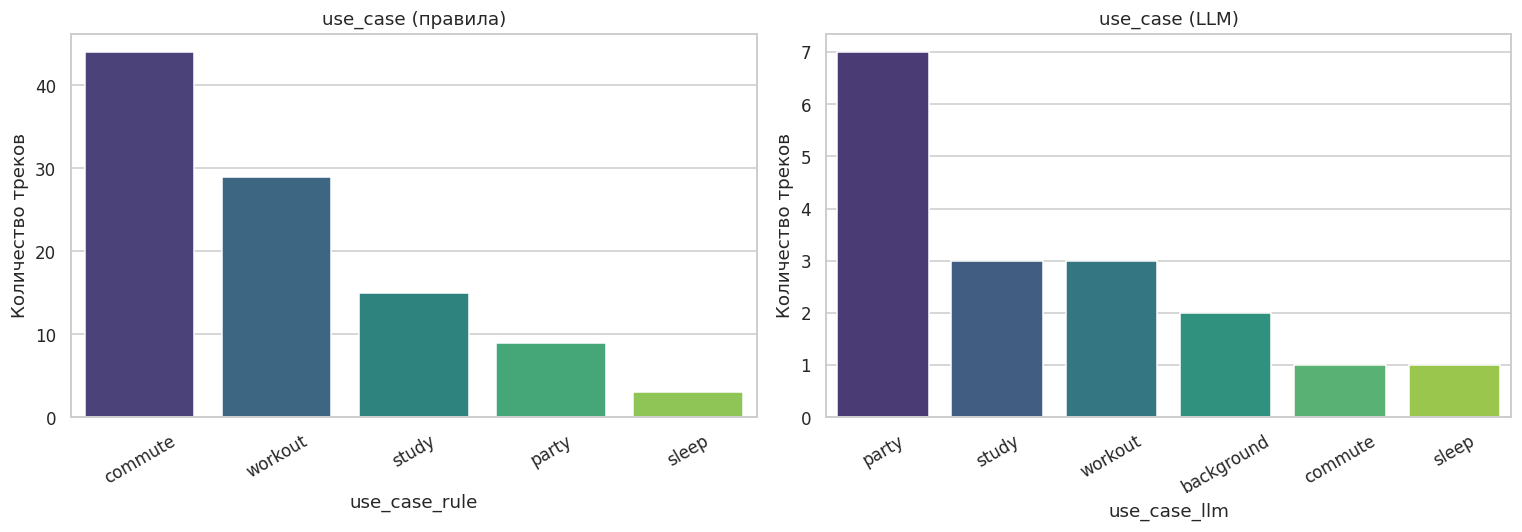

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

use_rule = tracks["use_case_rule"].value_counts()
sns.barplot(x=use_rule.index, y=use_rule.values, palette="viridis", ax=axes[0])
axes[0].set_title("use_case (правила)")
axes[0].set_ylabel("Количество треков")
axes[0].tick_params(axis="x", rotation=30)

use_llm = tracks["use_case_llm"].value_counts()
sns.barplot(x=use_llm.index, y=use_llm.values, palette="viridis", ax=axes[1])
axes[1].set_title("use_case (LLM)")
axes[1].set_ylabel("Количество треков")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1427/1580990727.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=atm_counts.values, y=atm_counts.index, palette="viridis")


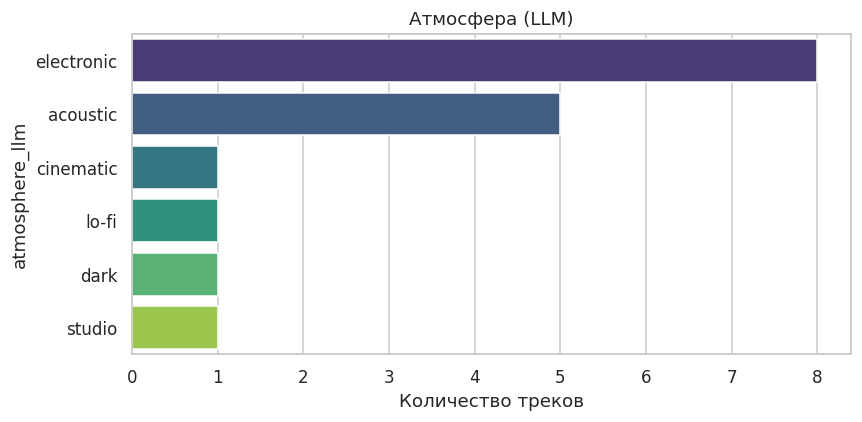

In [79]:
atm_counts = tracks["atmosphere_llm"].value_counts()
plt.figure(figsize=(8, 4))
sns.barplot(x=atm_counts.values, y=atm_counts.index, palette="viridis")
plt.title("Атмосфера (LLM)")
plt.xlabel("Количество треков")
plt.tight_layout()
plt.show()

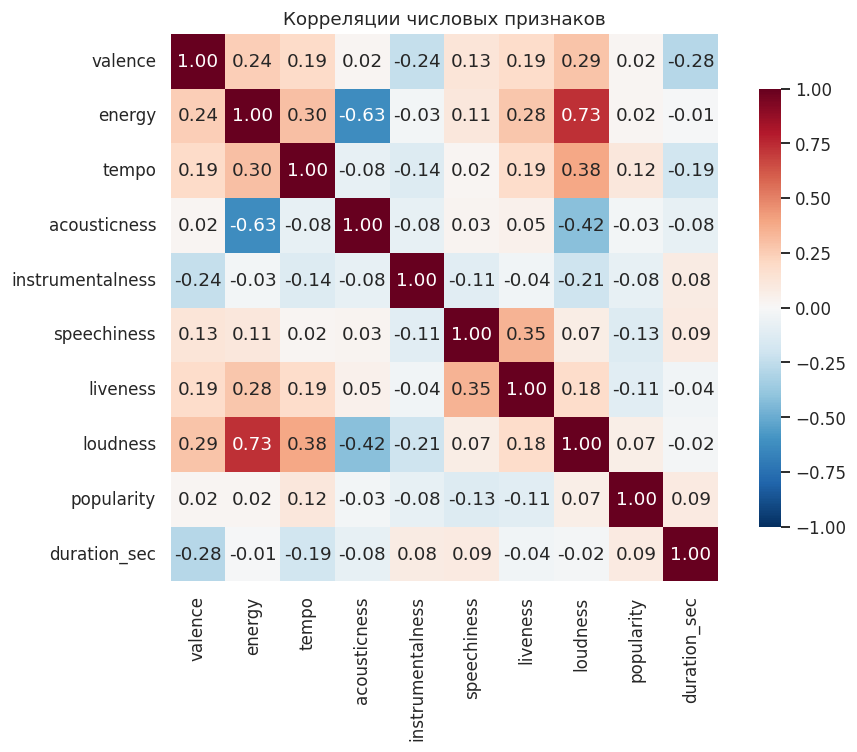

In [80]:
num_cols = ["valence", "energy", "tempo", "acousticness",
            "instrumentalness", "speechiness", "liveness",
            "loudness", "popularity", "duration_sec"]
num_cols = [c for c in num_cols if c in tracks.columns]

plt.figure(figsize=(9, 7))
corr = tracks[num_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()

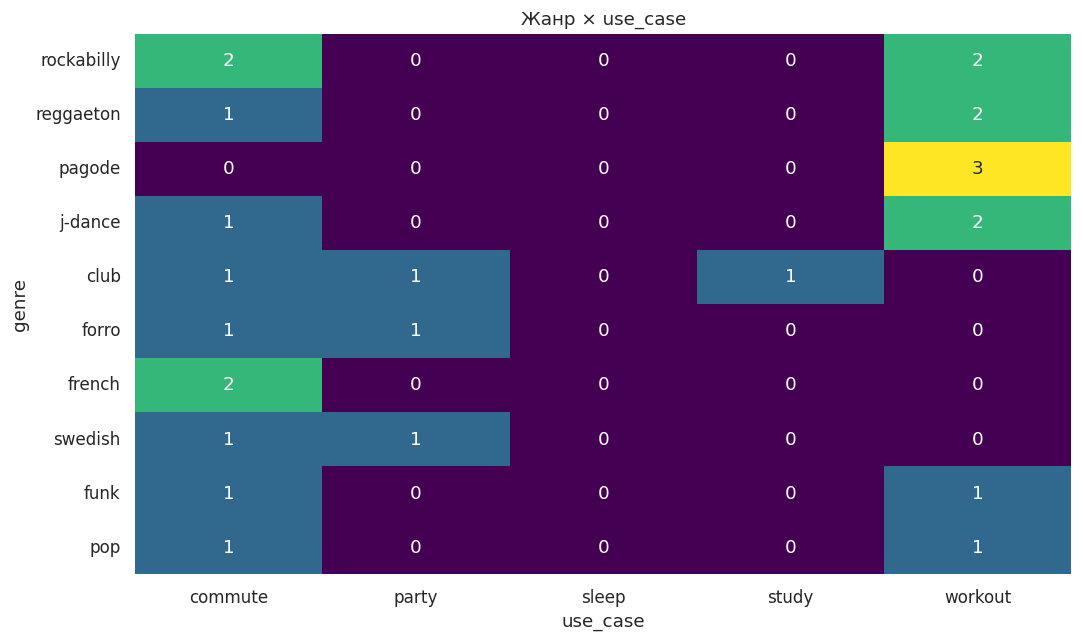

In [81]:
if "genre" in tracks.columns and "use_case" in tracks.columns:
    ct = pd.crosstab(tracks["genre"], tracks["use_case"])
    # берём топ-10 жанров, чтобы график не был нечитаемым
    top_genres = tracks["genre"].value_counts().head(10).index
    ct = ct.loc[top_genres]
    plt.figure(figsize=(10, 6))
    sns.heatmap(ct, annot=True, fmt="d", cmap="viridis", cbar=False)
    plt.title("Жанр × use_case")
    plt.tight_layout()
    plt.show()

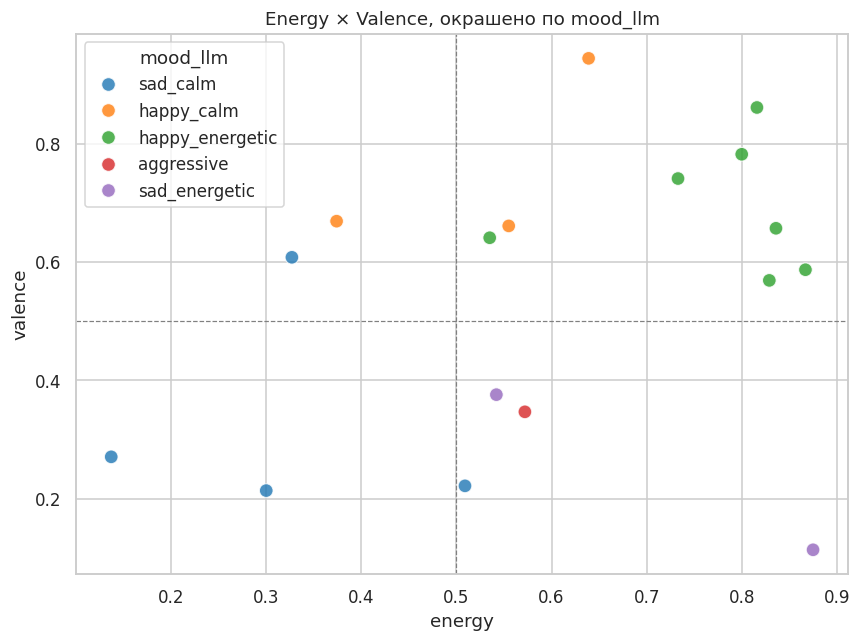

In [82]:
if "mood_llm" in tracks.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tracks, x="energy", y="valence",
                    hue="mood_llm", palette="tab10", s=80, alpha=0.8)
    plt.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
    plt.axvline(0.5, color="gray", linestyle="--", linewidth=0.8)
    plt.title("Energy × Valence, окрашено по mood_llm")
    plt.tight_layout()
    plt.show()

In [83]:
summary = pd.DataFrame({
    "Признак": ["жанр", "mood_rule", "mood_llm", "use_case_rule", "use_case_llm", "atmosphere_llm"],
    "Уникальных значений": [
        tracks["genre"].nunique(),
        tracks["mood_rule"].nunique(),
        tracks["mood_llm"].nunique(),
        tracks["use_case_rule"].nunique(),
        tracks["use_case_llm"].nunique(),
        tracks["atmosphere_llm"].nunique(),
    ],
    "Самая частая категория": [
        tracks["genre"].mode()[0],
        tracks["mood_rule"].mode()[0],
        tracks["mood_llm"].mode()[0],
        tracks["use_case_rule"].mode()[0],
        tracks["use_case_llm"].mode()[0],
        tracks["atmosphere_llm"].mode()[0],
    ],
    "Доля (%)": [
        round(tracks["genre"].value_counts(normalize=True).iloc[0] * 100, 1),
        round(tracks["mood_rule"].value_counts(normalize=True).iloc[0] * 100, 1),
        round(tracks["mood_llm"].value_counts(normalize=True).iloc[0] * 100, 1),
        round(tracks["use_case_rule"].value_counts(normalize=True).iloc[0] * 100, 1),
        round(tracks["use_case_llm"].value_counts(normalize=True).iloc[0] * 100, 1),
        round(tracks["atmosphere_llm"].value_counts(normalize=True).iloc[0] * 100, 1),
    ],
})
print(summary.to_string(index=False))

       Признак  Уникальных значений Самая частая категория  Доля (%)
          жанр                   68             rockabilly       4.0
     mood_rule                    4        happy_energetic      38.0
      mood_llm                    5        happy_energetic      41.2
 use_case_rule                    5                commute      44.0
  use_case_llm                    6                  party      41.2
atmosphere_llm                    6             electronic      47.1
